# 01 - EDA on UNSW-NB15

## 1. Loading the data

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd

from netad.data import (
    FEATURES, CATEGORICAL, NUMERIC,
    load_unsw_frame, load_unsw, deduplicate, resolve_conflicts, overlap_with_train,
)

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")
train_df.shape, test_df.shape

((175341, 45), (82332, 45))

In [4]:
X_train, y_train, y_train_multi = load_unsw("train")
X_test, y_test, y_test_multi = load_unsw("test")
X_train.shape, X_test.shape

((175341, 42), (82332, 42))

### Duplicates and train/test overlap

In [5]:
train_dedup = deduplicate(train_df)
len(train_df), len(train_dedup), len(train_df) - len(train_dedup)

(175341, 107740, 67601)

In [6]:
in_train = overlap_with_train(train_df, test_df)
in_train.sum(), (~in_train).sum()

(np.int64(8541), np.int64(73791))

In [7]:
overlap = pd.DataFrame({
    "test": test_df["attack_cat"].value_counts(),
    "in_train": test_df.loc[in_train, "attack_cat"].value_counts(),
}).fillna(0).astype(int)
overlap["share"] = (overlap["in_train"] / overlap["test"]).round(3)
overlap.sort_values("share", ascending=False)

,test,in_train,share
attack_cat,,,
DoS,4089,2004,0.490
Reconnaissance,3496,1138,0.326
Analysis,677,125,0.185
Exploits,11132,1802,0.162
Generic,18871,1722,0.091
Fuzzers,6062,261,0.043
Normal,37000,1472,0.040
Shellcode,378,13,0.034
Backdoor,583,4,0.007


The overlap is very uneven: 49% of DoS test rows (and 33% of Reconnaissance) are copies of train rows, against 4% of Normal and none of Worms.
Scores for these classes on the full test set will look better than on the unseen rows.

### Conflicting labels
Same feature vector, different label. Counted on raw train rows.

In [8]:
for target in ["label", "attack_cat"]:
    n_values = train_df.groupby(FEATURES)[target].transform("nunique")
    rows = train_df[n_values > 1]
    print(f"{target}: {len(rows)} rows ({len(rows) / len(train_df):.1%}), "
          f"{len(rows[FEATURES].drop_duplicates())} vectors")

label: 940 rows (0.5%), 229 vectors


attack_cat: 30528 rows (17.4%), 1772 vectors


In [9]:
conflict = train_df.groupby(FEATURES)["attack_cat"].transform("nunique") > 1
pd.DataFrame({
    "rows": train_df["attack_cat"].value_counts(),
    "in_conflict": train_df.loc[conflict, "attack_cat"].value_counts(),
}).assign(share=lambda t: (t["in_conflict"] / t["rows"]).round(3)).sort_values("share", ascending=False)

,rows,in_conflict,share
attack_cat,,,
DoS,12264,9746,0.795
Backdoor,1746,1340,0.767
Analysis,2000,1441,0.720
Exploits,33393,13299,0.398
Reconnaissance,10491,1889,0.180
Fuzzers,18184,2078,0.114
Worms,130,13,0.100
Generic,40000,319,0.008
Normal,56000,396,0.007


Rows per class after each policy (+ deduplicate):

In [10]:
counts = {"dedup only": deduplicate(train_df)["attack_cat"].value_counts()}
for target in ["label", "attack_cat"]:
    for policy in ["drop", "majority"]:
        resolved = deduplicate(resolve_conflicts(train_df, target, policy))
        counts[f"{target} / {policy}"] = resolved["attack_cat"].value_counts()

table = pd.DataFrame(counts)
table.loc["total"] = table.sum()
table

,dedup only,label / drop,label / majority,attack_cat / drop,attack_cat / majority
attack_cat,,,,,
Analysis,1594,1594,1594,393,393
Backdoor,1535,1535,1535,403,403
DoS,3806,3806,3806,2477,2691
Exploits,19844,19844,19844,18417,19227
Fuzzers,16150,15922,16004,14602,14684
Generic,4181,4181,4181,3904,3904
Normal,51890,51661,51709,51661,51709
Reconnaissance,7522,7522,7522,6209,6213
Shellcode,1091,1090,1090,1085,1086


Decision: `resolve_conflicts(..., policy="majority")` on the task's own target (`label` for binary, `attack_cat` for multi-class), then `deduplicate`. Test set is not touched.

On `attack_cat` most of Analysis, Backdoor and DoS go away with either policy, their flows mostly share feature vectors with other classes.

Same check on the test set, which is left as is:

In [11]:
test_conflict = test_df.groupby(FEATURES)["attack_cat"].transform("nunique") > 1
pd.DataFrame({
    "rows": test_df["attack_cat"].value_counts(),
    "in_conflict": test_df.loc[test_conflict, "attack_cat"].value_counts(),
}).fillna(0).astype(int).assign(share=lambda t: (t["in_conflict"] / t["rows"]).round(3)).sort_values("share", ascending=False)

,rows,in_conflict,share
attack_cat,,,
Analysis,677,619,0.914
Backdoor,583,526,0.902
DoS,4089,2830,0.692
Exploits,11132,3190,0.287
Fuzzers,6062,1257,0.207
Reconnaissance,3496,346,0.099
Worms,44,1,0.023
Shellcode,378,1,0.003
Generic,18871,31,0.002


In [12]:
test_counts = test_df.groupby(FEATURES + ["attack_cat"]).size()
best = test_counts == test_counts.groupby(level=FEATURES).transform("max")

print("max multi-class accuracy:", round(test_counts.groupby(level=FEATURES).max().sum() / len(test_df), 3))
print("label conflicts in test:", int((test_df.groupby(FEATURES)["label"].transform("nunique") > 1).sum()), "rows")
(test_counts[best].groupby(level="attack_cat").sum() / test_counts.groupby(level="attack_cat").sum()).sort_values().round(3)

max multi-class accuracy: 0.936


label conflicts in test: 14 rows


attack_cat
Analysis          0.086
Backdoor          0.111
DoS               0.838
Exploits          0.839
Reconnaissance    0.909
Fuzzers           0.952
Generic           0.999
Normal            1.000
Shellcode         1.000
Worms             1.000
dtype: float64

Upper bound on test, from a predictor that sees each vector and answers with its most frequent class (ties counted as correct).
91% of Analysis and 90% of Backdoor test rows share their vector with another class, so no model can get more than ~9% recall on Analysis or ~11% on Backdoor, and multi-class accuracy is capped at ~94%. Binary is not affected (14 rows).

## 2. Class distribution

In [13]:
dist = pd.DataFrame({
    "train": y_train_multi.value_counts(),
    "train %": y_train_multi.value_counts(normalize=True).mul(100).round(1),
    "test": y_test_multi.value_counts(),
    "test %": y_test_multi.value_counts(normalize=True).mul(100).round(1),
})
dist

,train,train %,test,test %
attack_cat,,,,
Normal,56000,31.9,37000,44.9
Generic,40000,22.8,18871,22.9
Exploits,33393,19.0,11132,13.5
Fuzzers,18184,10.4,6062,7.4
DoS,12264,7.0,4089,5.0
Reconnaissance,10491,6.0,3496,4.2
Analysis,2000,1.1,677,0.8
Backdoor,1746,1.0,583,0.7
Shellcode,1133,0.6,378,0.5


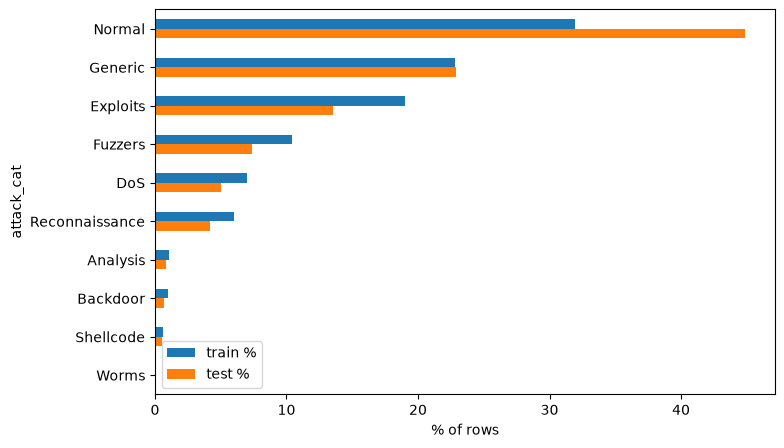

In [14]:
import matplotlib.pyplot as plt

ax = dist[["train %", "test %"]].plot.barh(figsize=(8, 5))
ax.invert_yaxis()
ax.set_xlabel("% of rows")
plt.show()

- Attacks are the majority: 68% of train, 55% of test. Real traffic is the other way around.
- Normal goes from 32% (train) to 45% (test), so class priors shift between the two files.
- Worms has 130 train rows, Shellcode, Backdoor and Analysis are around 1% each.

## 3. Feature types

In [15]:
for col in CATEGORICAL:
    unseen = sorted(set(test_df[col]) - set(train_df[col]))
    print(f"{col}: {train_df[col].nunique()} values in train, {test_df[col].nunique()} in test, unseen in test: {unseen}")

proto: 133 values in train, 131 in test, unseen in test: []
service: 13 values in train, 13 in test, unseen in test: []
state: 9 values in train, 7 in test, unseen in test: ['ACC', 'CLO']


In [16]:
train_df["proto"].value_counts().head(8)

proto
tcp     79946
udp     63283
unas    12084
arp      2859
ospf     2595
sctp     1150
any       300
gre       225
Name: count, dtype: int64

In [17]:
train_df["service"].value_counts()

service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
dhcp           94
snmp           80
ssl            56
irc            25
radius         12
Name: count, dtype: int64

In [18]:
test_df["state"].value_counts()

state
FIN    39339
INT    34163
CON     6982
REQ     1842
ACC        4
RST        1
CLO        1
Name: count, dtype: int64

`proto` has a long tail (133 values, most of them rare). `service == "-"` means no service was identified (54% of train).
Two `state` values (`ACC`, `CLO`) appear only in test, 5 rows in total, so the encoder in phase 2 has to handle unknown categories.

In [19]:
train_df.isna().sum().sum(), test_df.isna().sum().sum()

(np.int64(0), np.int64(0))

In [20]:
[c for c in NUMERIC if train_df[c].nunique() <= 2]

['is_sm_ips_ports']

In [21]:
train_df["is_ftp_login"].value_counts()

is_ftp_login
0    172774
1      2545
4        16
2         6
Name: count, dtype: int64

In [22]:
for name, df in [("train", train_df), ("test", test_df)]:
    same = (df["is_ftp_login"] == df["ct_ftp_cmd"])
    print(name, same.all(), (~same).sum())

train True 0
test False 8


`is_ftp_login` is not binary (0, 1, 2, 4). In train it is identical to `ct_ftp_cmd` row by row, in test the two differ on a few rows.
Both are kept for now, to revisit in phase 4 (feature importance).

## 4. Skewed features

In [23]:
train_df[NUMERIC].skew().sort_values(ascending=False).head(10).round(1)

trans_depth          167.3
response_body_len     76.3
sbytes                45.3
sloss                 44.8
dloss                 41.4
spkts                 40.2
dbytes                39.8
dpkts                 36.8
dinpkt                29.7
djit                  29.5
dtype: float64

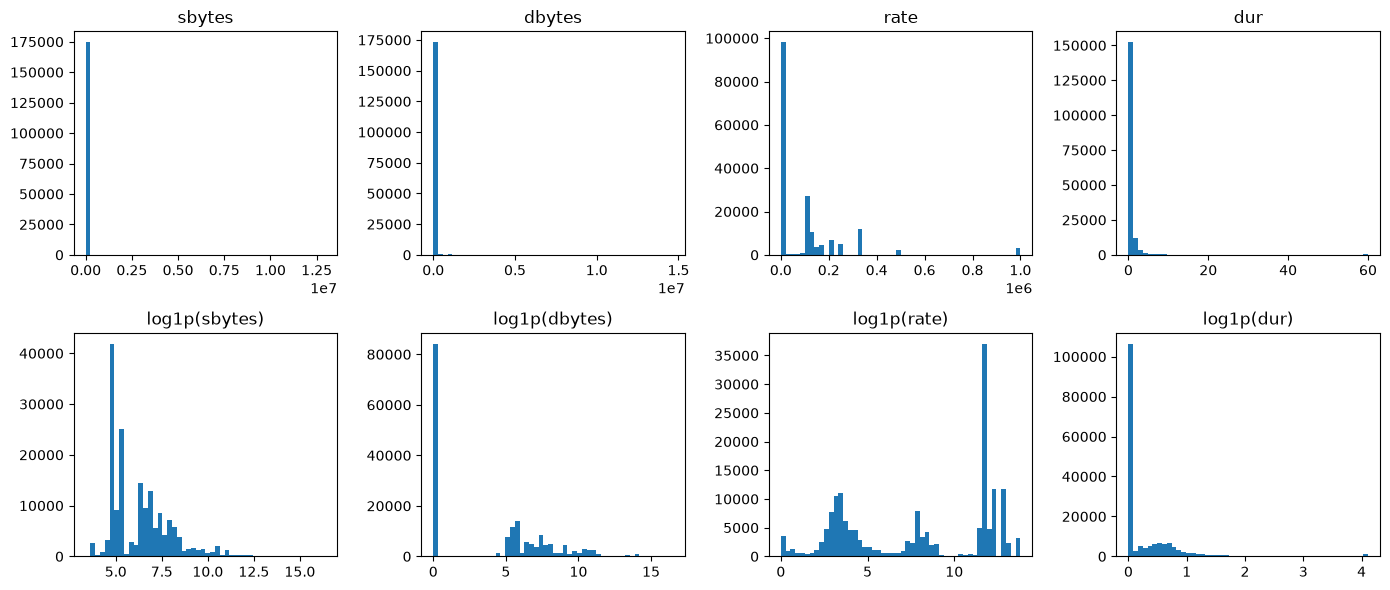

In [24]:
import numpy as np

cols = ["sbytes", "dbytes", "rate", "dur"]
fig, axes = plt.subplots(2, len(cols), figsize=(14, 6))
for i, col in enumerate(cols):
    axes[0, i].hist(train_df[col], bins=50)
    axes[0, i].set_title(col)
    axes[1, i].hist(np.log1p(train_df[col]), bins=50)
    axes[1, i].set_title(f"log1p({col})")
fig.tight_layout()
plt.show()

In [25]:
(train_df[NUMERIC] < 0).sum().sum(), (test_df[NUMERIC] < 0).sum().sum()

(np.int64(0), np.int64(0))

Byte, packet, load and loss counters have very long right tails. No negative values, so `log1p` can be applied to all numeric columns in phase 2.

## 5. Shortcut features (TTL)

In [26]:
train_df.groupby("sttl")["label"].agg(["size", "mean"]).sort_values("size", ascending=False).head(6).round(3)

,size,mean
sttl,,
254,114743,0.902
31,39455,0.000
62,17681,0.877
0,3162,0.096
64,181,0.000
1,64,0.000


In [27]:
test_df.groupby("sttl")["label"].agg(["size", "mean"]).sort_values("size", ascending=False).head(6).round(3)

,size,mean
sttl,,
254,54049,0.722
31,16702,0.000
62,10374,0.602
0,1048,0.058
29,50,0.000
1,38,0.000


In [28]:
train_df.groupby("ct_state_ttl")["label"].agg(["size", "mean"]).sort_values("size", ascending=False).head(6).round(3)

,size,mean
ct_state_ttl,,
2,82054,0.933
1,49355,0.824
0,40791,0.022
6,1930,0.552
3,1211,0.159


In [29]:
from sklearn.tree import DecisionTreeClassifier

print("always 'attack':", round((y_test == 1).mean(), 3))
for cols in [["sttl"], ["dttl"], ["ct_state_ttl"], ["sttl", "dttl", "ct_state_ttl"]]:
    tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(train_df[cols], y_train)
    print(cols, round(tree.score(test_df[cols], y_test), 3))

always 'attack': 0.551
['sttl'] 0.766
['dttl'] 0.754
['ct_state_ttl'] 0.775
['sttl', 'dttl', 'ct_state_ttl'] 0.787


`sttl == 31` is always normal, `sttl == 254` is 90% attack in train (72% in test). A depth-3 tree on the TTL columns alone gets ~0.79 test accuracy, against 0.55 for always predicting attack.
TTL depends on the testbed (how many hops the packets went through), not on what the attack does. Phase 4 will retrain without `sttl`, `dttl`, `ct_state_ttl` to see how much the models rely on them.

## 6. Feature groups

Groups as in the official UNSW-NB15 feature list (49 columns: 47 features + `attack_cat` and `label`). The train/test files keep 41 of the features plus `rate`.

| Group | Columns in these files |
|---|---|
| Flow | `proto` (`srcip`, `sport`, `dstip`, `dsport` are not in these files) |
| Basic | `state`, `dur`, `sbytes`, `dbytes`, `sttl`, `dttl`, `sloss`, `dloss`, `service`, `sload`, `dload`, `spkts`, `dpkts` |
| Content | `swin`, `dwin`, `stcpb`, `dtcpb`, `smean`, `dmean`, `trans_depth`, `response_body_len` |
| Time | `sjit`, `djit`, `sinpkt`, `dinpkt`, `tcprtt`, `synack`, `ackdat` (`stime`, `ltime` are not in these files) |
| General purpose | `is_sm_ips_ports`, `ct_state_ttl`, `ct_flw_http_mthd`, `is_ftp_login`, `ct_ftp_cmd` |
| Connection | `ct_srv_src`, `ct_srv_dst`, `ct_dst_ltm`, `ct_src_ltm`, `ct_src_dport_ltm`, `ct_dst_sport_ltm`, `ct_dst_src_ltm` |
| Not in the official list | `rate` |

Some names differ from the feature list: `smeansz` -> `smean`, `sintpkt` -> `sinpkt`, `res_bdy_len` -> `response_body_len`.
The connection counters are computed over the last 100 connections, so they carry a bit of context beyond the single flow.

## 7. Summary

- 175k train / 82k test flows, 42 features (3 categorical), no missing values. Attacks are the majority and the class mix differs between train and test.
- 38.6% of train rows are exact duplicates. 10.4% of test rows also appear in train, very unevenly: 49% of DoS, 33% of Reconnaissance, 4% of Normal.
- 17.4% of train rows share their feature vector with a different `attack_cat`, mostly DoS, Backdoor and Analysis. Train is cleaned, test is not, so on test multi-class accuracy can't go above ~94% and recall on Analysis and Backdoor can't go above ~10%. Weak scores on these classes are expected. Binary is not affected.
- Counters are heavily skewed (log1p), `proto` has a long tail and test has `state` values not seen in train.
- TTL columns alone separate a large part of the traffic; this is likely a testbed artefact.

Data handling from here on: `train_val_split` cleans train for the task's target (`resolve_conflicts(..., "majority")`, then one row per feature vector) and holds out 20% for validation; test is used as is, and results are reported on the full test set and on the rows not seen in train.